## Contrail lifetime as a function of RHi and temperature

A 2D heatmap of contrail lifetime binned by the IAGOS relative humidity w.r.t. ice (`rhi_iagos_oldest`) and temperature (`temp_iagos_oldest`) at the oldest annotated contrail point, mirroring the "Observation" panel style: temperature on the y-axis, RHi on the x-axis, and contrail lifetime (s) shown on a log colour scale. Bins backed by a single observation are hatched to flag low confidence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
# 2D heatmap of contrail lifetime as a function of RHi and Temperature,
# using the IAGOS state at the oldest annotated contrail point (the "Observation"
# panel style of Driver et al., where colour = contrail lifetime on a log scale).

df_life = pd.read_csv(
    "../data/landsat_sentinel_collocations_20260216_lifetimes_included.csv",
    comment="#",
).dropna(subset=["lifetime", "temp_iagos_oldest", "rhi_iagos_oldest"])


In [3]:
df_life

,path,satellite,scene_id,sensing_time,crs,extent,visualization_url,base_url,icao24,registration,...,efficiency_PS_ERA5,efficiency_BADA4_ERA5,temp_iagos_oldest,rhl_iagos_oldest,rhi_iagos_oldest,air_pressure_iagos_oldest,dtlc_iagos_oldest,lifetime,length,oldest_time
345,intersects_sentinel/2022/2022050908551904_L1C_...,Sentinel,L1C_T17TNJ_A035930_20220509T162807,2022-05-09 16:31:15.658000+00:00,EPSG:32617,"[499980.0, 609770.0, 4790230.0, 4900020.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/17/T/NJ/...,3C64F4,D-AIGT,...,0.324879,0.294508,215.479996,0.344,0.606419,20680.0,-6.455549,2.312532,548.070072,2022-05-09T16:31:13.345468000
346,intersects_sentinel/2022/2022062908482306_L1C_...,Sentinel,L1C_T20TPP_A027750_20220629T150819,2022-06-29 15:10:44.508000+00:00,EPSG:32620,"[600000.0, 709790.0, 4790230.0, 4900020.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/20/T/PP/...,3C6565,D-AIKE,...,0.341730,0.320566,218.320007,0.366,0.627665,20660.0,-3.939310,4.566096,968.012249,2022-06-29T15:10:39.941904000
347,intersects_sentinel/2022/2022052209384906_L1C_...,Sentinel,L1C_T10UFA_A027209_20220522T190752,2022-05-22 19:10:39.635000+00:00,EPSG:32610,"[600000.0, 709790.0, 5490250.0, 5600040.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/10/U/FA/...,3C6565,D-AIKE,...,0.333876,0.307788,214.279999,0.266,0.474389,20660.0,-7.449638,8.810885,2149.855989,2022-05-22T19:10:30.824114000
348,intersects_sentinel/2022/2022082109054916_L1C_...,Sentinel,L1C_T20UPB_A028508_20220821T151652,2022-08-21 15:18:43.571000+00:00,EPSG:32620,"[600000.0, 709790.0, 5590210.0, 5700000.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/20/U/PB/...,3C656F,D-AIKO,...,0.338749,0.318341,212.600006,0.539,0.976958,20670.0,-10.548693,104.162938,22915.846274,2022-08-21T15:16:59.408062000
349,intersects_sentinel/2022/2022112310280404_L1C_...,Sentinel,L1C_T31UGS_A038758_20221123T104502,2022-11-23 10:46:51.193000+00:00,EPSG:32631,"[699960.0, 809750.0, 5590210.0, 5700000.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/31/U/GS/...,3C656F,D-AIKO,...,0.333092,0.230069,223.830002,0.398,0.646790,29790.0,-1.994620,9.551534,2089.859033,2022-11-23T10:46:41.641465000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
728,intersects_sentinel/2018/2018122902525214_L1C_...,Sentinel,L1C_T48NXJ_A018376_20181229T031726,2018-12-29 03:27:06.717019+00:00,EPSG:32648,"[600000.0, 709790.0, 290230.0, 400020.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/48/N/XJ/...,8991BE,B-18317,...,0.343525,0.312659,219.759995,0.701,1.185429,19680.0,-3.994051,201.940936,49879.411098,2018-12-29T03:23:44.776083000
730,intersects_sentinel/2018/2018041509555906_L1C_...,Sentinel,L1C_T32TMT_A014691_20180415T103544,2018-04-15 10:35:44.550000+00:00,EPSG:32632,"[399960.0, 509750.0, 5190250.0, 5300040.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/32/T/MT/...,392F34,F-GLZU,...,0.321514,0.314482,218.830002,0.619,1.056288,26190.0,-6.891338,44.420862,10544.957344,2018-04-15T10:35:00.129138000
732,intersects_sentinel/2018/2018033014184608_L1C_...,Sentinel,L1C_T13TEG_A005558_20180330T174936,2018-03-30 17:52:22.093240+00:00,EPSG:32613,"[499980.0, 609770.0, 4590250.0, 4700040.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/13/T/EG/...,A46AD6,N384HA,...,0.312712,0.281686,211.830002,0.353,0.644582,22720.0,-10.478781,85.640537,17898.872198,2018-03-30T17:50:56.452703000
738,intersects_sentinel/2018/2018043009161612_L1C_...,Sentinel,L1C_T32TKK_A005997_20180430T103520,2018-04-30 10:39:46.835370+00:00,EPSG:32632,"[199980.0, 309770.0, 4390210.0, 4500000.0]",https://browser.dataspace.copernicus.eu/?zoom=...,gs://gcp-public-data-sentinel-2/tiles/32/T/KK/...,39644E,

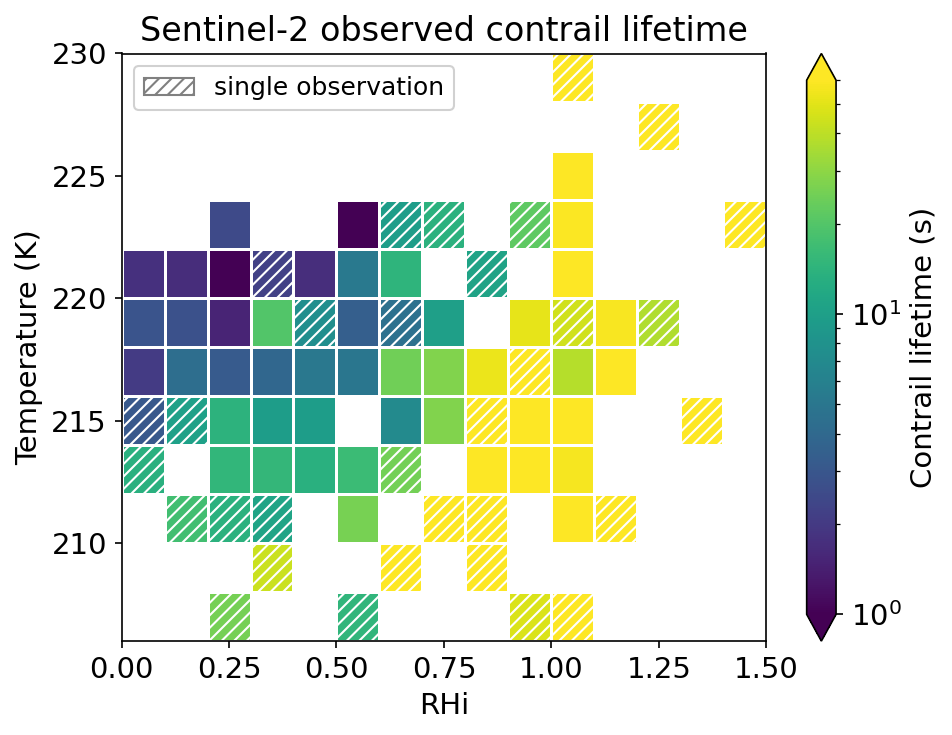

In [6]:

rhi  = df_life["rhi_iagos_oldest"].values
temp = df_life["temp_iagos_oldest"].values
life = df_life["lifetime"].values

rhi = df_life["rhi_iagos"].values
temp = df_life["air_temperature_iagos"].values

# Bin edges in RHi (x) and temperature (y)
rhi_edges  = np.arange(0.0, 1.5 + 1e-9, 0.1)
temp_edges = np.arange(206, 230 + 1e-9, 2.0)

# Mean lifetime and sample count per bin
sum_life, _, _ = np.histogram2d(rhi, temp, bins=[rhi_edges, temp_edges], weights=life)
count, _, _    = np.histogram2d(rhi, temp, bins=[rhi_edges, temp_edges])
with np.errstate(invalid="ignore"):
    mean_life = sum_life / count
mean_life[count == 0] = np.nan

# Transpose so rows = temperature (y), cols = RHi (x) for pcolormesh
mean_life = mean_life.T
count = count.T

plt.rcParams.update({
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
})

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=150)

norm = mcolors.LogNorm(vmin=1.0, vmax=np.nanmax(mean_life))
norm = mcolors.LogNorm(vmin=1.0, vmax=60)

pcm = ax.pcolormesh(
    rhi_edges, temp_edges, np.ma.masked_invalid(mean_life),
    cmap="viridis", norm=norm, shading="flat",
    edgecolors="white", linewidth=0.5,
)

# Hatch bins backed by a single observation to flag low confidence
sparse = count == 1
for i in range(count.shape[0]):
    for j in range(count.shape[1]):
        if sparse[i, j]:
            ax.add_patch(plt.Rectangle(
                (rhi_edges[j], temp_edges[i]),
                rhi_edges[j + 1] - rhi_edges[j],
                temp_edges[i + 1] - temp_edges[i],
                facecolor="none", edgecolor="white", hatch="////", linewidth=0.0,
            ))

ax.set_xlabel("RHi")
ax.set_ylabel("Temperature (K)")
ax.set_title("Sentinel-2 observed contrail lifetime")
ax.set_xlim(rhi_edges[0], rhi_edges[-1])
ax.set_ylim(temp_edges[0], temp_edges[-1])

hatch_legend = [Patch(facecolor="white", edgecolor="grey", hatch="////",
                      label="single observation")]
ax.legend(handles=hatch_legend, loc="upper left", framealpha=0.9)

cbar = fig.colorbar(pcm, ax=ax, extend="both")
cbar.set_label("Contrail lifetime (s)")

fig.tight_layout()
plt.savefig("../figures/fig07_temp_rhi_lifetime.png", dpi=300, bbox_inches="tight", pad_inches=0.1)
plt.show()